# AI251P Capstone – Phase 1 (M1–M3): CBIS-DDSM Benign vs. Malignant Classification

**GitHub Repository:** https://github.com/ziyad-Moh/AI251P-CBIS-DDSM
**Reproducibility:** The exact Git commit hash is recorded in the repository README.
**Scope of this notebook (Phase 1):** Dataset preparation and documentation (M1), a CNN trained from scratch (M2), and transfer learning using ResNet-18 (M3).

| Part | Content |
|---|---|
| M1 | Image matching, data cleaning, duplicate removal, patient-level data splitting, label audit, data augmentation, and dataset card |
| M2 | CNN trained from scratch, training curves, model checkpoints, error analysis, classification metrics, confusion matrices, and calibration |
| M3 | Pretrained ResNet-18 with frozen, partial, and full fine-tuning, model comparison, test evaluation, and data improvement analysis |

All reported results are based on the specified data split, image resolution (`IMG_SIZE`), and classification threshold (0.5 unless stated otherwise).

**Disclaimer:** This project is for academic purposes only. It is not a medical diagnostic tool and must not be used for clinical decisions.

## 0. Experimental Setup, Configuration, and Reproducibility

In [2]:
import os, re, sys, glob, hashlib, random, json, time, math
from collections import defaultdict
from functools import lru_cache

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
import torch.nn as nn
from tqdm.auto import tqdm

# ------------------------------ configuration ------------------------------
SEED          = 42
BASE_PATH     = "/content/cbis_ddsm"
IMG_SIZE      = 64           # ROI crops are padded to a square and resized to IMG_SIZE x IMG_SIZE (results in this notebook were obtained at 64; 128 needs a GPU re-run)
BATCH_SIZE    = 64
NUM_WORKERS   = 0
PRETRAINED    = True         # ImageNet weights for ResNet-18 (needs internet in Colab)
OVERLAP_POLICY = "drop_from_train"
USE_WANDB     = False          # run the W&B login cell first
WANDB_PROJECT = "ai251p-cbis-ddsm"
OUT_DIR       = "outputs"
CKPT_DIR      = "checkpoints"
VAL_FRACTION_FOLDS = 5       # 1 of 5 patient-grouped folds of the official train set -> validation (~20%)
PATIENCE      = 8            # early stopping on validation ROC-AUC
RUNS = {                     # name: (epochs, learning rate)
    "scratch_cnn":      (40, 1e-3),
    "resnet18_frozen":  (20, 1e-3),
    "resnet18_partial": (25, 3e-4),
    "resnet18_full":    (25, 1e-4),
}
# ---------------------------------------------------------------------------

CSV_PATH  = f"{BASE_PATH}/csv"
JPEG_PATH = f"{BASE_PATH}/jpeg"
for d in (OUT_DIR, CKPT_DIR):
    os.makedirs(d, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    print("WARNING: no GPU found. In Colab use Runtime > Change runtime type > T4 GPU.")


def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)


set_seed()
print("device:", device, "| torch", torch.__version__, "| python", sys.version.split()[0])

device: cuda | torch 2.14.1+cu130 | python 3.13.16


### Weights & Biases (Colab only)

In [ ]:
import wandb
wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


In [ ]:
import subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wandb"], check=True)
import wandb
wandb.login()   # paste your API key when asked

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


In [5]:
try:
    import wandb
except ImportError:
    wandb = None


class Tracker:
    """Thin W&B wrapper. Falls back to no-op (with a warning) if W&B is unavailable."""
    def __init__(self, enabled):
        self.enabled = bool(enabled and wandb is not None)
        self.run = None
        if enabled and wandb is None:
            print("WARNING: wandb not installed -> runs are NOT tracked.")

    def start(self, name, config, job_type="train"):
        if not self.enabled:
            return
        try:
            self.run = wandb.init(project=WANDB_PROJECT, name=name, config=config, job_type=job_type)
        except Exception as e:
            print("WARNING: W&B init failed, tracking disabled:", e)
            self.enabled, self.run = False, None

    def log(self, d):
        if self.run is not None:
            self.run.log(d)

    def summary(self, d):
        if self.run is not None:
            self.run.summary.update(d)

    def log_fig(self, key, fig):
        if self.run is not None:
            self.run.log({key: wandb.Image(fig)})

    def finish(self):
        if self.run is not None:
            self.run.finish(); self.run = None


tracker = Tracker(USE_WANDB)

### Download dataset

In [4]:
import os

print("CSV files:", len(os.listdir("/content/cbis_ddsm/csv")))
print("JPEG folders:", len(os.listdir("/content/cbis_ddsm/jpeg")))

CSV files: 6
JPEG folders: 6774


In [3]:
!pip install kaggle

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


!kaggle datasets download -d awsaf49/cbis-ddsm-breast-cancer-image-dataset

!unzip cbis-ddsm-breast-cancer-image-dataset.zip -d cbis_ddsm

import os

base_path = "/content/cbis_ddsm"

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)
    indent = " " * 2 * level
    print(f"{indent}{os.path.basename(root)}/")
    if level < 2:
        for f in files[:5]:
            print(f"{indent}  {f}")

import os
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm

IMG_SIZE = 64

def preprocess_image(image_path):
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    if image is None:
        return None

    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
    image = image / 255.0
    image = image.flatten()

    return image

Streaming output truncated to the last 5000 lines.
    1.3.6.1.4.1.9590.100.1.2.321301320011325872020779457512539076961/
    1.3.6.1.4.1.9590.100.1.2.121645143012539735840742788344033655105/
    1.3.6.1.4.1.9590.100.1.2.241579586612341854529296644293103293624/
    1.3.6.1.4.1.9590.100.1.2.25808746612056028922655832353262270502/
    1.3.6.1.4.1.9590.100.1.2.275882615212993080933361025713032556573/
    1.3.6.1.4.1.9590.100.1.2.86045443713025653826957804903976346265/
    1.3.6.1.4.1.9590.100.1.2.397716189412021206209859104030103071713/
    1.3.6.1.4.1.9590.100.1.2.220316302711097599628755669793690089945/
    1.3.6.1.4.1.9590.100.1.2.90066757213729410240080160501989256297/
    1.3.6.1.4.1.9590.100.1.2.75888639012130774840181006431587214557/
    1.3.6.1.4.1.9590.100.1.2.115315087010396173033334275991639287548/
    1.3.6.1.4.1.9590.100.1.2.386168523211665458004517044830846292598/
    1.3.6.1.4.1.9590.100.1.2.321225274412631915214047330560159121583/
    1.3.6.1.4.1.9590.100.1.2.35485952231068

## 1. Load CSVs and Create Binary Labels

The official CBIS-DDSM training and test datasets are used. Mass and calcification cases are combined before checking for data leakage.

Pathology labels are converted into binary classes:
- **0:** Benign (including BENIGN_WITHOUT_CALLBACK)
- **1:** Malignant

The official test set is preserved, while the training data is later divided into training and validation sets at the patient level to prevent data leakage.

In [6]:
def load_split(case, split):
    df = pd.read_csv(f"{CSV_PATH}/{case}_case_description_{split}_set.csv")
    df["case_type"] = "mass" if case == "mass" else "calcification"
    df["split"] = split
    return df

raw = pd.concat([load_split(c, s) for c in ("mass", "calc") for s in ("train", "test")],
                ignore_index=True)

# clean stray whitespace/newlines in path columns
for col in ["image file path", "cropped image file path", "ROI mask file path"]:
    raw[col] = raw[col].astype(str).str.strip()

# explicit label mapping (fails loudly on unknown values)
LABEL_MAP = {"BENIGN": 0, "BENIGN_WITHOUT_CALLBACK": 0, "MALIGNANT": 1}
unknown = set(raw["pathology"].unique()) - set(LABEL_MAP)
assert not unknown, f"Unknown pathology values: {unknown}"
raw["label"] = raw["pathology"].map(LABEL_MAP)

raw["row_key"] = (raw["case_type"] + "_" + raw["patient_id"].astype(str) + "_" +
                  raw["left or right breast"].astype(str) + "_" + raw["image view"].astype(str) + "_" +
                  raw["abnormality id"].astype(str) + "_" + raw["split"])

print("Rows:", raw.shape[0])
print(pd.crosstab([raw["split"], raw["case_type"]], raw["pathology"], margins=True))

Rows: 3568
pathology            BENIGN  BENIGN_WITHOUT_CALLBACK  MALIGNANT   All
split case_type                                                      
test  calcification     130                       67        129   326
      mass              194                       37        147   378
train calcification     528                      474        544  1546
      mass              577                      104        637  1318
All                    1429                      682       1457  3568


## 2. Match CSV Rows to JPEG Files

The CSV files contain DICOM-style image paths, while the JPEG dataset is organized using unique identifiers (UIDs).

To ensure reliable image matching, the matching process was improved to avoid selecting incorrect files.

The following rules are applied:

- **No match or unreadable image:** The row is excluded and recorded in the matching log.
- **Ambiguous matches:** Rows with multiple plausible image candidates are excluded rather than selecting a file randomly.
- **Mask detection:** Images that appear to be binary ROI masks are identified using pixel intensity analysis.
- **Swapped paths:** If the cropped image and ROI mask paths are swapped in the CSV, the correct cropped image is recovered using the ROI mask column.

All matching decisions and exclusion reasons are recorded in `outputs/match_log.csv`.

In [7]:
UID_RE = re.compile(r"1\.3\.6\.1\.4\.1\.9590[.\d]*\d")
MASK_EXTREME_FRAC = 0.98   # >98% of pixels <=10 or >=245  ->  looks like a binary ROI mask
OK_STATUSES = {"ok", "ok_disambiguated", "swapped_fixed"}

image_files = [f for f in glob.glob(f"{JPEG_PATH}/**/*", recursive=True)
               if os.path.isfile(f) and f.lower().endswith((".jpg", ".jpeg", ".png"))]
print("Image files found:", len(image_files))

uid_to_files = defaultdict(list)
for fp in image_files:
    for uid in UID_RE.findall(fp):
        uid_to_files[uid].append(fp)
print("Unique UIDs indexed:", len(uid_to_files),
      "| UIDs with >1 file:", sum(len(v) > 1 for v in uid_to_files.values()))


def read_gray(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Could not read image: {path}")
    return img


@lru_cache(maxsize=None)
def inspect_file(path):
    """Read a file once: readability, md5 of the bytes, shape, mask-likeness."""
    try:
        data = np.fromfile(path, dtype=np.uint8)
        img = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)
    except Exception:
        img, data = None, None
    if img is None or img.size == 0:
        return {"ok": False, "md5": None, "shape": None, "mask_like": False}
    extreme = float(((img <= 10) | (img >= 245)).mean())
    return {"ok": True, "md5": hashlib.md5(data.tobytes()).hexdigest(),
            "shape": img.shape, "mask_like": extreme > MASK_EXTREME_FRAC}


def candidates_for(csv_path):
    """Most specific UID first (series folder); returns the files stored under it."""
    for uid in reversed(UID_RE.findall(str(csv_path))):
        if uid in uid_to_files:
            return sorted(set(uid_to_files[uid]))
    return []


def non_mask_candidates(csv_path):
    cands = candidates_for(csv_path)
    info = [(p, inspect_file(p)) for p in cands]
    readable = [(p, i) for p, i in info if i["ok"]]
    good = [p for p, i in readable if not i["mask_like"]]
    return cands, readable, good


def resolve_row(row):
    cands, readable, good = non_mask_candidates(row["cropped image file path"])
    if not cands:
        return None, "no_match"
    if not readable:
        return None, "unreadable"
    if len(good) == 1:
        return good[0], ("ok" if len(cands) == 1 else "ok_disambiguated")
    if len(good) > 1:
        return None, "ambiguous"
    # every candidate looks like a mask -> try the ROI-mask column (paths are sometimes swapped)
    _, _, good2 = non_mask_candidates(row["ROI mask file path"])
    if len(good2) == 1:
        return good2[0], "swapped_fixed"
    return None, "mask_like"


res = [resolve_row(r) for _, r in tqdm(raw.iterrows(), total=len(raw), desc="matching")]
raw["matched_image_path"] = [p for p, _ in res]
raw["match_status"] = [s for _, s in res]

print(pd.crosstab(raw["match_status"], raw["split"], margins=True))
raw[["row_key", "split", "case_type", "cropped image file path", "matched_image_path", "match_status"]] \
    .to_csv(f"{OUT_DIR}/match_log.csv", index=False)

Image files found: 10237
Unique UIDs indexed: 6774 | UIDs with >1 file: 3463


matching: 100%|██████████| 3568/3568 [03:04<00:00, 19.29it/s]

split             test  train   All
match_status                       
no_match             0      1     1
ok                  11     92   103
ok_disambiguated   693   2770  3463
swapped_fixed        0      1     1
All                704   2864  3568


**Visual Inspection of Randomly Matched Images**

A random sample of matched images was visually inspected to verify that each image represents a cropped breast tissue region (ROI), rather than a binary mask or a full mammogram.

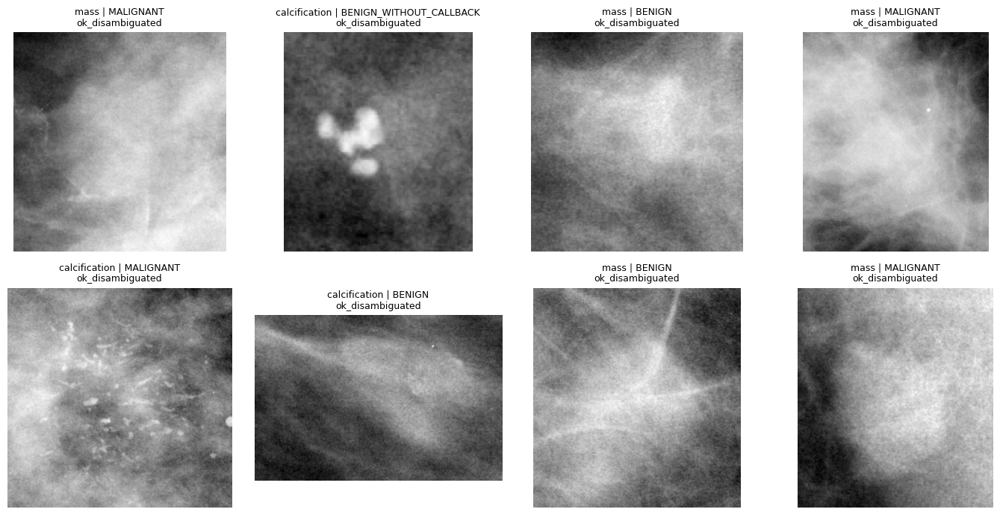

In [8]:
ok_rows = raw[raw["match_status"].isin(OK_STATUSES)]
sample = ok_rows.sample(min(8, len(ok_rows)), random_state=SEED)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(read_gray(r["matched_image_path"]), cmap="gray")
    ax.set_title(f'{r["case_type"]} | {r["pathology"]}\n{r["match_status"]}', fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Data Cleaning: Unreadable Images, Masks, and Duplicates

All excluded rows are saved in `outputs/excluded_files.csv` with the reason for exclusion.

We used MD5 hashes to find duplicate images. The following rules were applied:

- If the same image had different labels, all copies were removed.
- If an image appeared in both train and test, the train copy was removed and the test copy was kept.
- If an image appeared more than once in the same split, only one copy was kept.

These steps helped remove duplicates and avoid data leakage.

In [9]:
excluded = []


def log_excluded(r, reason):
    excluded.append({"row_key": r["row_key"], "split": r["split"], "case_type": r["case_type"],
                     "patient_id": r["patient_id"], "csv_cropped_path": r["cropped image file path"],
                     "matched_path": r["matched_image_path"], "reason": reason})


# (a) rows that could not be matched safely
for _, r in raw[~raw["match_status"].isin(OK_STATUSES)].iterrows():
    log_excluded(r, r["match_status"])

ok = raw[raw["match_status"].isin(OK_STATUSES)].copy()
ok["file_md5"] = ok["matched_image_path"].map(lambda p: inspect_file(p)["md5"])

# (b) duplicates
drop = {}
for h, g in ok.groupby("file_md5"):
    if len(g) < 2:
        continue
    if g["label"].nunique() > 1:                      # same image, different labels
        for i in g.index:
            drop[i] = "duplicate_label_conflict"
        continue
    has_test = (g["split"] == "test").any()
    keep = g.index[g["split"] == "test"][0] if has_test else g.index[0]
    for i in g.index:
        if i == keep:
            continue
        drop[i] = ("duplicate_cross_split" if (g.loc[i, "split"] == "train" and has_test)
                   else "duplicate_within_split")

for i, reason in drop.items():
    log_excluded(ok.loc[i], reason)
clean = ok.drop(index=list(drop))

print("Raw rows:", len(raw), "| excluded so far:", len(excluded), "| remaining:", len(clean))
print(pd.Series([e["reason"] for e in excluded]).value_counts().to_string() if excluded else "Nothing excluded")

Raw rows: 3568 | excluded so far: 1 | remaining: 3567
no_match    1


In [18]:
suspect_idx = [1, 6, 24, 41, 66, 72, 77]

cols = [
    "patient_id",
    "case_type",
    "image view",
    "pathology",
    "row_key",
    "matched_image_path"
]

for i in suspect_idx:
    print(f"\nAUDIT INDEX: {i}")
    print(audit.iloc[i][cols].to_string())


AUDIT INDEX: 1
patient_id                                                      P_01630
case_type                                                          mass
image view                                                          MLO
pathology                                                        BENIGN
row_key                                  mass_P_01630_RIGHT_MLO_1_train
matched_image_path    /content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...

AUDIT INDEX: 6
patient_id                                                      P_00243
case_type                                                 calcification
image view                                                           CC
pathology                                                     MALIGNANT
row_key                           calcification_P_00243_LEFT_CC_1_train
matched_image_path    /content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...

AUDIT INDEX: 24
patient_id                                                      P_00812
case_type      

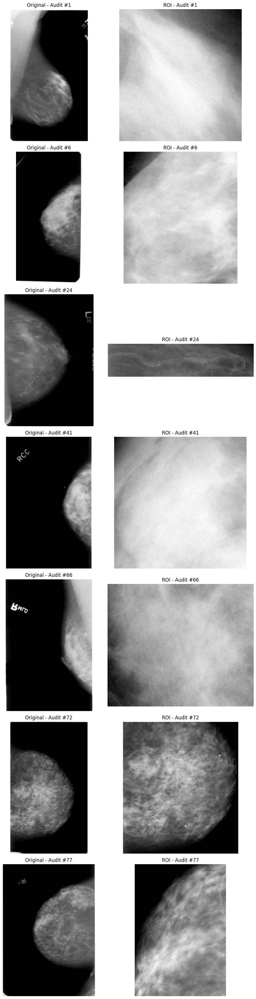

In [19]:
import matplotlib.pyplot as plt
from PIL import Image

suspect_idx = [1, 6, 24, 41, 66, 72, 77]

fig, axes = plt.subplots(7, 2, figsize=(10, 35))

for row, idx in enumerate(suspect_idx):
    r = audit.iloc[idx]

    uids = str(r["image file path"]).split("/")
    candidates = [
        p for p in image_files
        if any(uid in p for uid in uids[1:-1])
    ]

    original = candidates[0] if len(candidates) == 1 else None
    roi = r["matched_image_path"]

    for ax, path, title in [
        (axes[row, 0], original, f"Original - Audit #{idx}"),
        (axes[row, 1], roi, f"ROI - Audit #{idx}")
    ]:
        if path:
            ax.imshow(Image.open(path).convert("L"), cmap="gray")
        else:
            ax.text(0.5, 0.5, "No unique match",
                    ha="center", va="center")
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
plt.show()

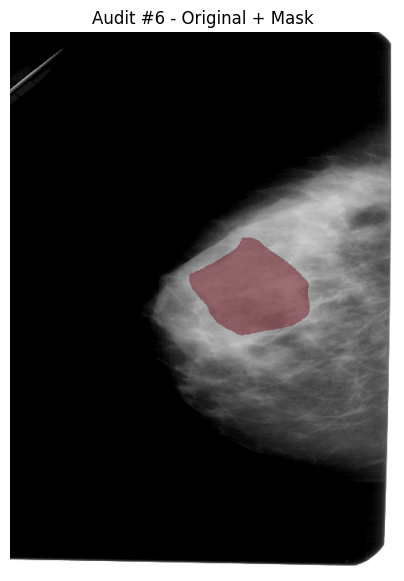

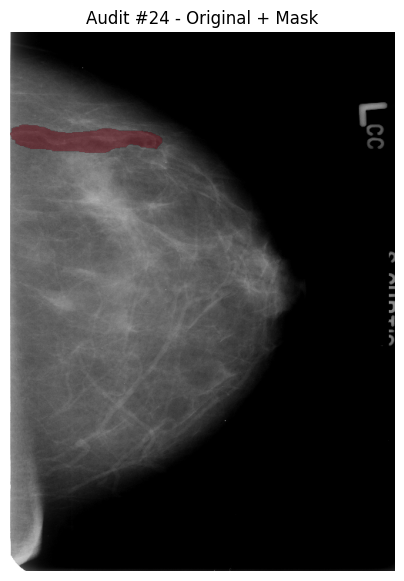

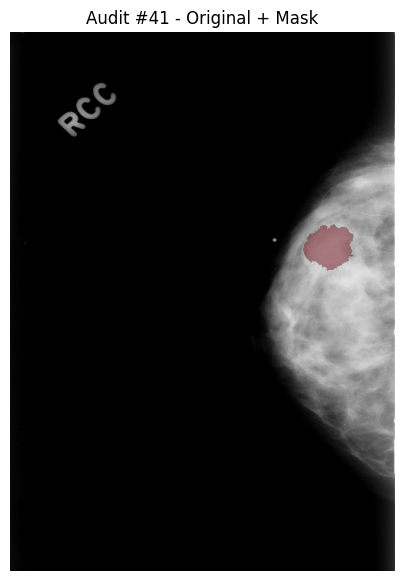

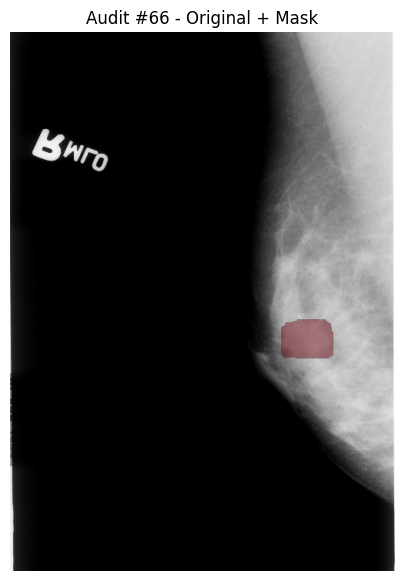

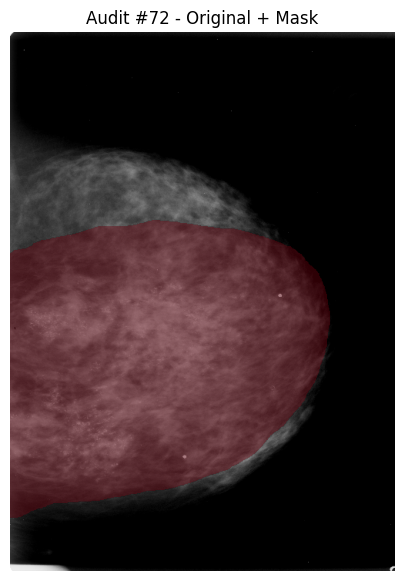

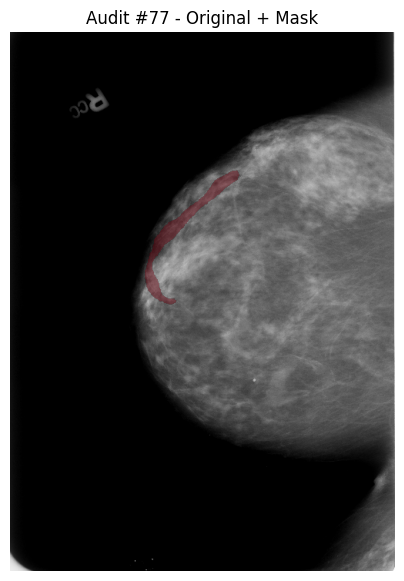

In [29]:
remaining = [6, 24, 41, 66, 72, 77]

for i in remaining:
    r = audit.iloc[i]

    original_uid = str(r["image file path"]).split("/")[-2]
    mask_uid = str(r["ROI mask file path"]).split("/")[-2]

    original_path = next(
        p for p in image_files if original_uid in p
    )

    mask_path = next(
        p for p in image_files
        if mask_uid in p
        and os.path.normpath(p) != os.path.normpath(r["matched_image_path"])
    )

    orig = cv2.imread(original_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    orig = cv2.resize(orig, (500, 700))
    mask = cv2.resize(
        mask, (500, 700),
        interpolation=cv2.INTER_NEAREST
    )

    plt.figure(figsize=(5, 7))
    plt.imshow(orig, cmap="gray")
    plt.imshow(
        np.ma.masked_where(mask <= 127, mask),
        cmap="Reds",
        alpha=0.45,
        vmin=0,
        vmax=255
    )
    plt.title(f"Audit #{i} - Original + Mask")
    plt.axis("off")
    plt.show()
    plt.close()

In [30]:
import cv2
import numpy as np
import pandas as pd
from itertools import combinations

# Perceptual hash (pHash)
def phash_image(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    img = cv2.resize(img, (32, 32))
    dct = cv2.dct(np.float32(img))
    low = dct[:8, :8].flatten()
    median = np.median(low[1:])
    return low > median

# One hash per unique image path
paths = clean["matched_image_path"].dropna().unique()
hashes = {p: phash_image(p) for p in paths}

results = []
threshold = 10

# Compare images only within the same patient
for patient, group in clean.groupby("patient_id"):
    patient_paths = group["matched_image_path"].dropna().unique()
    for a, b in combinations(patient_paths, 2):
        if hashes[a] is None or hashes[b] is None:
            continue
        distance = int(np.count_nonzero(hashes[a] != hashes[b]))
        if distance <= threshold:
            results.append({
                "patient_id": patient,
                "image_1": a,
                "image_2": b,
                "phash_distance": distance
            })

near_duplicates = pd.DataFrame(
    results,
    columns=["patient_id", "image_1", "image_2", "phash_distance"]
)

print("Total images:", len(paths))
print("Unreadable images:", sum(h is None for h in hashes.values()))
print("Near-duplicate pairs:", len(near_duplicates))
print("Patients with near-duplicates:",
      near_duplicates["patient_id"].nunique())

near_duplicates.to_csv(
    f"{OUT_DIR}/near_duplicates.csv", index=False
)

display(near_duplicates.head(10))


Total images: 3567
Unreadable images: 0
Near-duplicate pairs: 6
Patients with near-duplicates: 2


,patient_id,image_1,image_2,phash_distance
0,P_01437,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,10
1,P_01437,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,10
2,P_01437,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,6
3,P_01437,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,10
4,P_01437,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,10
5,P_01740,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,10


### Near-Duplicate Check

We used perceptual hashing (pHash) to check for visually similar images within each patient. The check flagged 6 potentially similar image pairs from 2 patients, with pHash distances between 6 and 10. These pairs were treated as candidates for review rather than confirmed duplicates. Patient-level splitting was used to reduce the risk of data leakage.

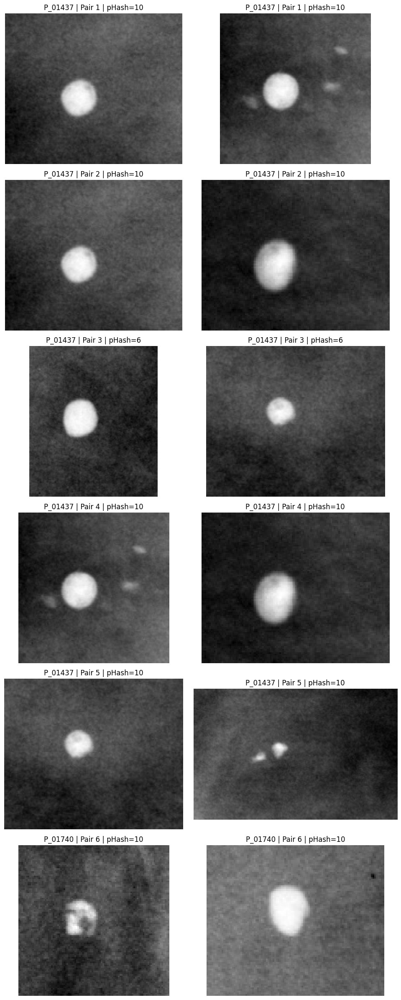

In [31]:
fig, axes = plt.subplots(len(near_duplicates), 2, figsize=(10, 4 * len(near_duplicates)))

for i, row in near_duplicates.reset_index(drop=True).iterrows():
    for j, col in enumerate(["image_1", "image_2"]):
        img = cv2.imread(row[col], cv2.IMREAD_GRAYSCALE)
        axes[i, j].imshow(img, cmap="gray")
        axes[i, j].set_title(
            f"{row['patient_id']} | Pair {i+1} | pHash={row['phash_distance']}"
        )
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

## 4. Patient-Level Data Leakage Check

Images from the same patient should not appear in both the training and test sets.

We combined mass and calcification cases before checking for patient overlap.

The check was performed twice:
- Before cleaning, using the original official train and test splits.
- After cleaning, to check whether any patients still appeared in both sets.

We found 31 overlapping patients and removed 83 training rows belonging to these patients, while keeping the official test data.

After this step, no patients were shared between the training and test sets.

In [32]:
def patient_overlap(df):
    tr = set(df.loc[df["split"] == "train", "patient_id"])
    te = set(df.loc[df["split"] == "test", "patient_id"])
    return tr & te


print("Overlapping patients in the official split (before cleaning):", len(patient_overlap(raw)))

overlap = patient_overlap(clean)
print("Overlapping patients after cleaning:", len(overlap))

if overlap:
    if OVERLAP_POLICY == "drop_from_train":
        rows = clean[(clean["split"] == "train") & clean["patient_id"].isin(overlap)]
        for _, r in rows.iterrows():
            log_excluded(r, "patient_overlap_train_test")
        clean = clean.drop(index=rows.index)
        print(f"Dropped {len(rows)} train rows belonging to overlapping patients (test kept as official).")
    else:
        raise ValueError(f"Unknown OVERLAP_POLICY: {OVERLAP_POLICY}")

assert len(patient_overlap(clean)) == 0, "Patient leakage still present!"
print("OK: no patient appears in both train and test.")

pd.DataFrame(excluded).to_csv(f"{OUT_DIR}/excluded_files.csv", index=False)
clean.drop(columns=["file_md5"]).to_csv(f"{OUT_DIR}/clean_manifest.csv", index=False)

print("\nFinal dataset:")
print(pd.crosstab([clean["split"], clean["case_type"]], clean["pathology"], margins=True))

Overlapping patients in the official split (before cleaning): 31
Overlapping patients after cleaning: 31
Dropped 83 train rows belonging to overlapping patients (test kept as official).
OK: no patient appears in both train and test.

Final dataset:
pathology            BENIGN  BENIGN_WITHOUT_CALLBACK  MALIGNANT   All
split case_type                                                      
test  calcification     130                       67        129   326
      mass              194                       37        147   378
train calcification     522                      449        518  1489
      mass              566                       98        627  1291
All                    1412                      651       1421  3484


## 5. Train, Validation, and Test Split

We divided the data into three sets:

- **Test:** The official CBIS-DDSM test set. It was kept separate and was not used during training or model selection.
- **Validation:** Created from the official training set using `StratifiedGroupKFold`. Images from the same patient were kept in the same split.
- **Training:** Used to train the four models.

We used the validation results to compare the models, select the best model, and apply early stopping.

The test set was used only for the final evaluation.

In [33]:
from sklearn.model_selection import StratifiedGroupKFold

test_patients = set(clean.loc[clean["split"] == "test", "patient_id"])

trainval = clean[
    (clean["split"] == "train") &
    (~clean["patient_id"].isin(test_patients))
].reset_index(drop=True)

test_meta = clean[clean["split"] == "test"].reset_index(drop=True)

sgkf = StratifiedGroupKFold(n_splits=VAL_FRACTION_FOLDS, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(trainval, trainval["label"], groups=trainval["patient_id"]))
train_meta = trainval.iloc[tr_idx].reset_index(drop=True)
val_meta   = trainval.iloc[va_idx].reset_index(drop=True)

split_meta = {"train": train_meta, "val": val_meta, "test": test_meta}
pat = {k: set(v["patient_id"]) for k, v in split_meta.items()}
assert not (pat["train"] & pat["val"]) and not (pat["train"] & pat["test"]) and not (pat["val"] & pat["test"]), \
    "Patient leakage between splits!"
print("OK: train / val / test share no patient.")

rows = []
for k, v in split_meta.items():
    rows.append({"split": k, "images": len(v), "patients": v["patient_id"].nunique(),
                 "malignant": int(v["label"].sum()), "malignant %": round(100 * v["label"].mean(), 1),
                 "mass": int((v["case_type"] == "mass").sum()),
                 "calcification": int((v["case_type"] == "calcification").sum())})
balance_df = pd.DataFrame(rows).set_index("split")
display(balance_df)

pd.concat([v.assign(split3=k)[["row_key", "patient_id", "case_type", "pathology", "label", "split3"]]
           for k, v in split_meta.items()]).to_csv(f"{OUT_DIR}/splits.csv", index=False)

OK: train / val / test share no patient.


,images,patients,malignant,malignant %,mass,calcification
split,,,,,,
train,2188,975,895,40.9,1029,1159
val,592,242,250,42.2,262,330
test,704,349,276,39.2,378,326


## 6. Label Audit

The pathology labels in CBIS-DDSM are based on biopsy results. They cannot be confirmed by looking at the images alone.

We performed two types of checks:

**1. Automatic Label Check**

We checked images belonging to the same patient and lesion using the case type, breast side, and abnormality ID. Images from different views were expected to have the same pathology label. Any differences were flagged for review.

**2. Manual Image Review**

We randomly selected 100 images from the training data and validation data and checked whether they showed the correct ROI crop.

No problems were recorded in the reviewed sample (0/100). The 95% upper confidence bound for the problem rate was 3.0%.

These checks help identify possible image and label mismatches, but they do not verify the original biopsy results.

In [34]:
key_cols = ["case_type", "patient_id", "left or right breast", "abnormality id"]
all_rows = pd.concat([v.assign(split3=k) for k, v in split_meta.items()], ignore_index=True)
g = all_rows.groupby(key_cols)
multi = g.filter(lambda x: len(x) > 1)
multi_groups = multi.groupby(key_cols)
inconsistent = multi_groups.filter(lambda x: x["label"].nunique() > 1)

n_multi = multi_groups.ngroups
n_bad = inconsistent.groupby(key_cols).ngroups if len(inconsistent) else 0
print(f"Lesion groups with >1 view: {n_multi} | groups with conflicting labels: {n_bad}"
      + (f" ({100 * n_bad / n_multi:.1f}%)" if n_multi else ""))
inconsistent[key_cols + ["image view", "pathology", "split3", "matched_image_path"]] \
    .sort_values(key_cols).to_csv(f"{OUT_DIR}/label_consistency_flags.csv", index=False)
inconsistent.head(10)

Lesion groups with >1 view: 1486 | groups with conflicting labels: 3 (0.2%)


,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,...,split,breast density,calc type,calc distribution,label,row_key,matched_image_path,match_status,file_md5,split3
229,P_00419,2.0,LEFT,CC,1,mass,OVAL,CIRCUMSCRIBED,3,BENIGN,...,train,NaN,NaN,NaN,0,mass_P_00419_LEFT_CC_1_train,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,ok_disambiguated,dbe9bd30f55a7a6a7f892ba9e9f7009d,train
230,P_00419,2.0,LEFT,CC,2,mass,NaN,ILL_DEFINED,5,MALIGNANT,...,train,NaN,NaN,NaN,1,mass_P_00419_LEFT_CC_2_train,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,ok_disambiguated,c60dcc489cead44d38f69089b46851e4,train
231,P_00419,2.0,LEFT,MLO,1,mass,NaN,ILL_DEFINED,5,MALIGNANT,...,train,NaN,NaN,NaN,1,mass_P_00419_LEFT_MLO_1_train,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,ok_disambiguated,80e7e3c95af10973cf12da13ea76d97f,train
232,P_00419,2.0,LEFT,MLO,2,mass,OVAL,CIRCUMSCRIBED,3,BENIGN,...,train,NaN,NaN,NaN,0,mass_P_00419_LEFT_MLO_2_train,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,ok_disambiguated,927358cf4014e26a4359c967057be64b,train
3108,P_01623,3.0,RIGHT,CC,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,...,test,NaN,NaN,NaN,1,mass_P_01623_RIGHT_CC_1_test,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,ok_disambiguated,3b7505d62290f0334313dee1c2ac3426,test
3109,P_01623,3.0,RIGHT,MLO,1,mass,IRREGULAR,SPICULATED,5,BENIGN,...,test,NaN,NaN,NaN,0,mass_P_01623_RIGHT_MLO_1_test,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,ok_disambiguated,7097d4f6c4499494cd676ede36ec2d56,test


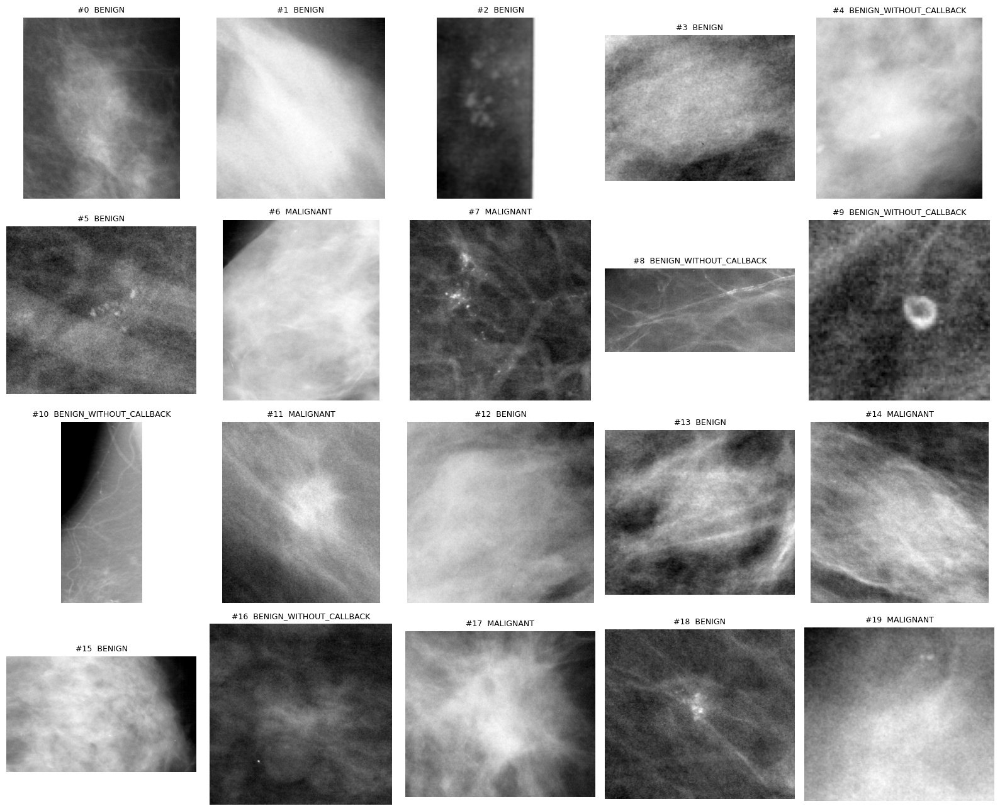

In [36]:
# ---- manual-review sample: 100 random train+val images (test is not reviewed) ----
AUDIT_SIZE = 100
audit = trainval.sample(min(AUDIT_SIZE, len(trainval)), random_state=SEED).reset_index(drop=True)
audit[["row_key", "matched_image_path", "pathology"]].assign(valid_roi="", note="") \
    .to_csv(f"{OUT_DIR}/audit_sample.csv", index=False)


def show_audit_page(page, per_page=20):
    sub = audit.iloc[page * per_page:(page + 1) * per_page]
    fig, axes = plt.subplots(4, 5, figsize=(16, 13))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (i, r) in zip(axes.ravel(), sub.iterrows()):
        ax.imshow(read_gray(r["matched_image_path"]), cmap="gray")
        ax.set_title(f"#{i}  {r['pathology']}", fontsize=9)
    plt.tight_layout(); plt.show()


show_audit_page(0)   # then 1, 2, 3, 4 ... note the indices of images that are NOT a valid ROI crop

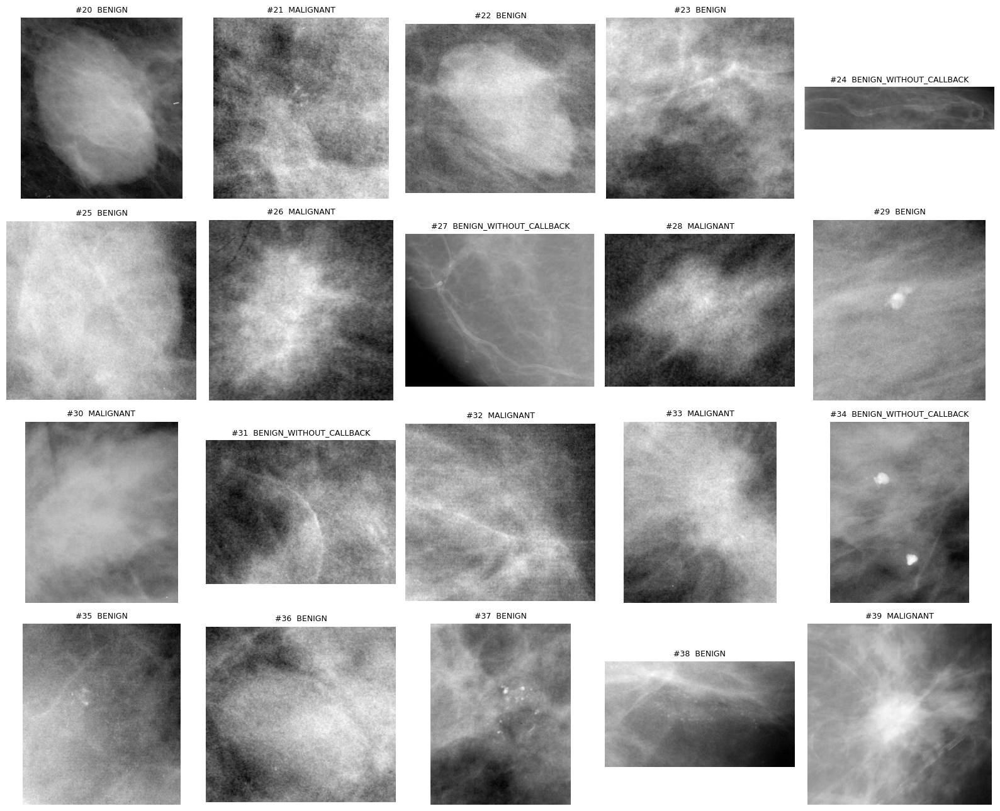

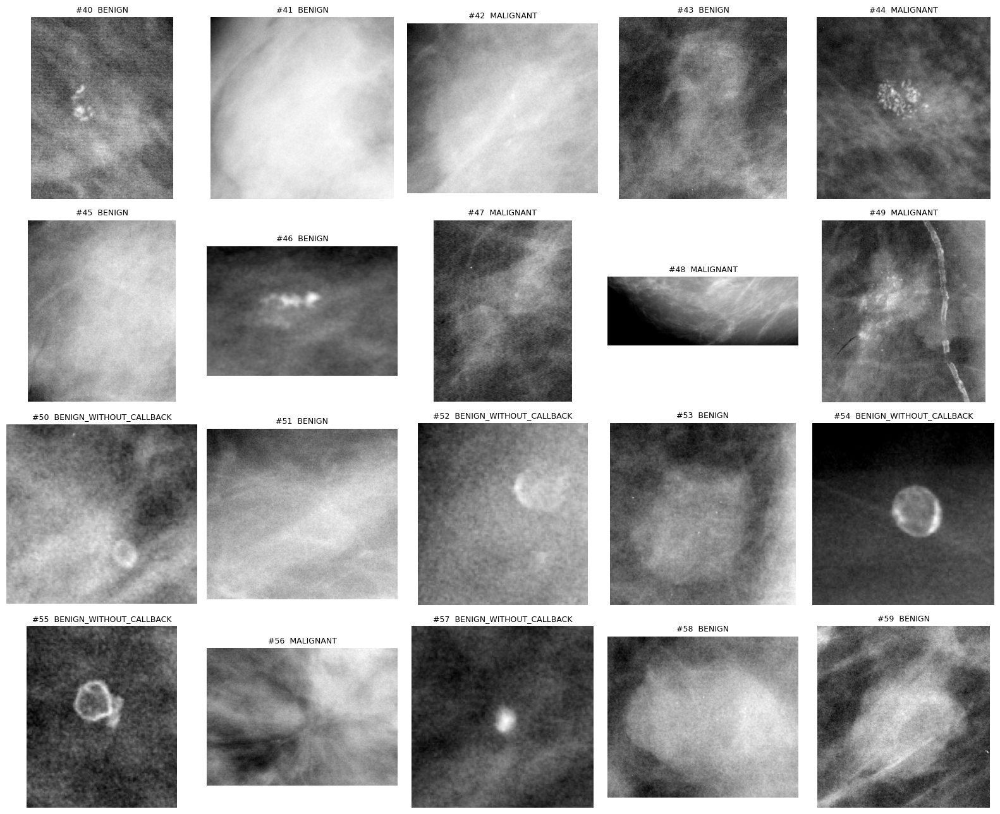

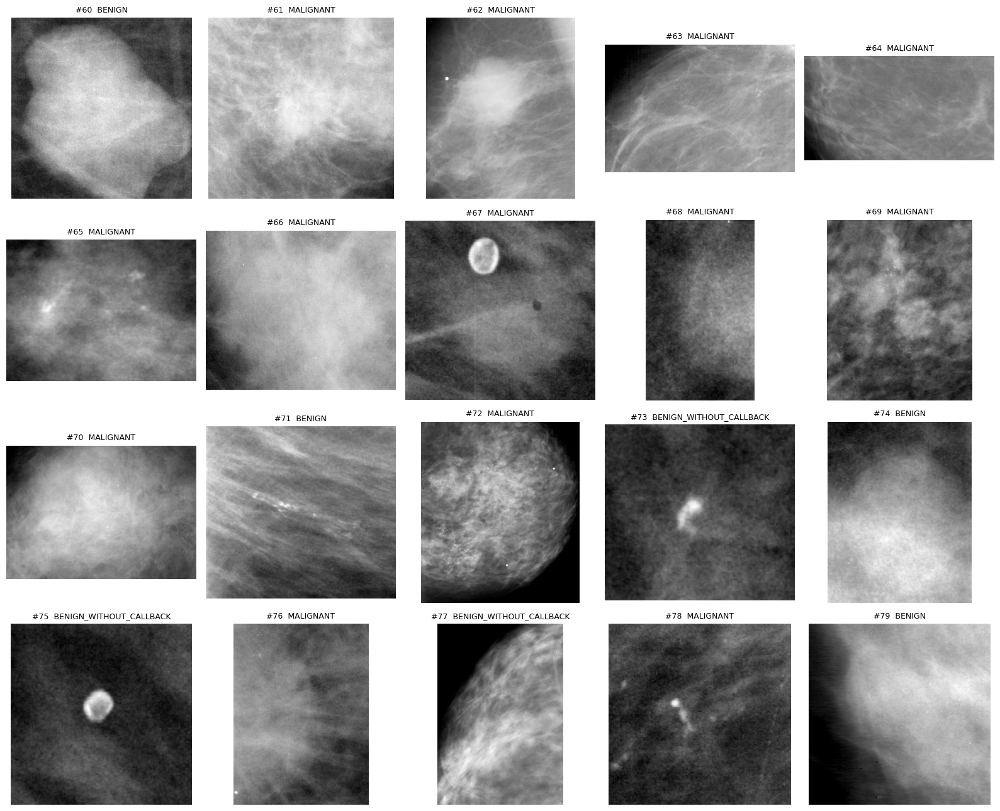

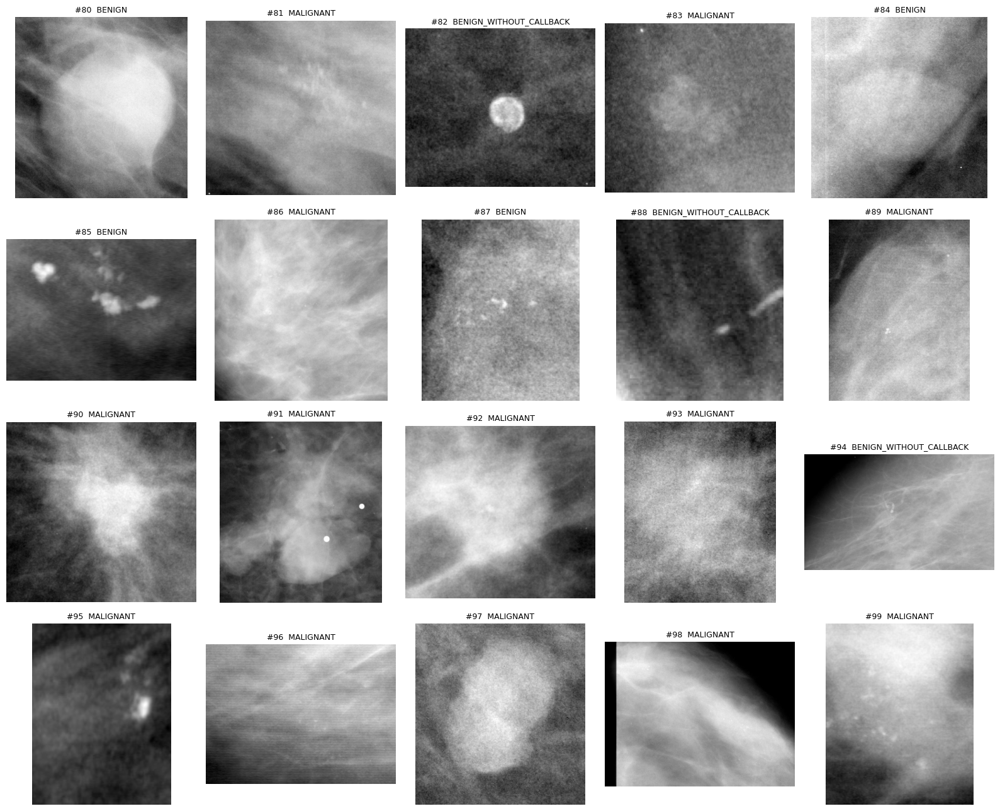

In [37]:
# remaining audit pages (page 0 was shown above); note the "#" of every image that is NOT a valid ROI crop
for page in range(1, (len(audit) + 19) // 20):
    show_audit_page(page)

In [38]:
from scipy.stats import beta

def clopper_pearson_upper(k, n, alpha=0.05):
    """One-sided (1-alpha) upper confidence bound for a rate after k problems in n reviewed images."""
    return 1.0 if k >= n else float(beta.ppf(1 - alpha, k + 1, n - k))


# ---- fill in AFTER reviewing ALL audit pages (0..4) ----
REVIEW_DONE = True   # set to True once every page has been reviewed
BAD_IDX = []          # the "#" numbers of images that are NOT a valid ROI crop of the labelled lesion, e.g. [12, 47]

assert all(0 <= i < len(audit) for i in BAD_IDX), "BAD_IDX contains an index outside the audit sample"
AUDIT_N      = len(audit) if REVIEW_DONE else None
AUDIT_ERRORS = len(set(BAD_IDX)) if REVIEW_DONE else None

if AUDIT_N is None or AUDIT_ERRORS is None:
    audit_summary = "pending (manual review not completed yet)"
    print("Manual review pending: review all pages above, fill BAD_IDX, then set REVIEW_DONE = True and re-run.")
else:
    ub = clopper_pearson_upper(AUDIT_ERRORS, AUDIT_N)
    audit_summary = (f"{AUDIT_ERRORS}/{AUDIT_N} problems found; 95% upper bound on the problem rate = {100 * ub:.1f}%")
    print(audit_summary)

0/100 problems found; 95% upper bound on the problem rate = 3.0%


## 7. Data Loading and Augmentation

The ROI images have different sizes and shapes, so we first padded each image with black pixels to make it square, then resized it to `IMG_SIZE` without changing its aspect ratio.

All images were loaded into memory as `uint8` tensors to make data loading faster during training.

We applied the following transformations:

- **Training:** Random horizontal and vertical flips, rotation, small shifts, scaling, and brightness and contrast changes.
- **Validation and Test:** Only conversion to float and normalization were applied.

The mean and standard deviation were calculated using the training images only to avoid data leakage.

In [39]:
def read_gray(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Could not read image: {path}")
    return img


def load_square(path, size=IMG_SIZE):
    img = read_gray(path)
    h, w = img.shape
    s = max(h, w)
    canvas = np.zeros((s, s), dtype=np.uint8)
    canvas[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = img
    return cv2.resize(canvas, (size, size), interpolation=cv2.INTER_AREA)


def build_tensor(df):
    imgs = [load_square(p) for p in tqdm(df["matched_image_path"], desc="loading", leave=False)]
    X = torch.from_numpy(np.stack(imgs)).unsqueeze(1)        # N x 1 x H x W, uint8
    y = torch.tensor(df["label"].to_numpy(), dtype=torch.long)
    return X, y


X_tr, y_tr = build_tensor(train_meta)
X_va, y_va = build_tensor(val_meta)
X_te, y_te = build_tensor(test_meta)
print("train", tuple(X_tr.shape), "| val", tuple(X_va.shape), "| test", tuple(X_te.shape))

MEAN = float((X_tr.float() / 255).mean())
STD  = float((X_tr.float() / 255).std())
print(f"train mean={MEAN:.4f} std={STD:.4f}")

train (2188, 1, 64, 64) | val (592, 1, 64, 64) | test (704, 1, 64, 64)
train mean=0.4049 std=0.2588


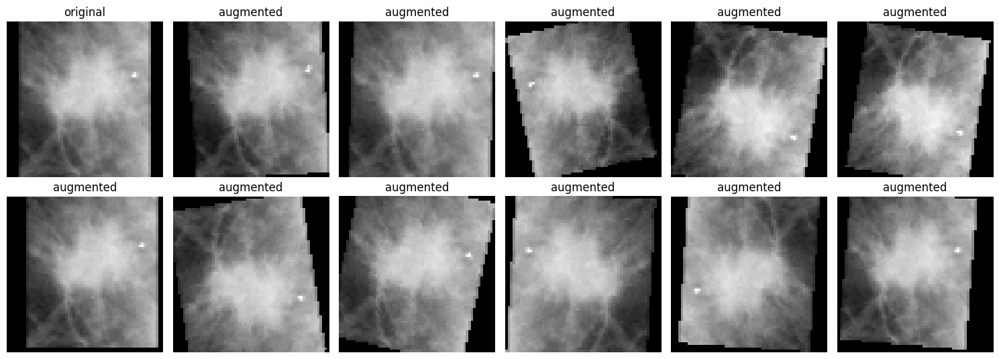

In [40]:
from torchvision.transforms import v2

train_tf = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomVerticalFlip(),
    v2.RandomAffine(degrees=15, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    v2.ColorJitter(brightness=0.2, contrast=0.2),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize([MEAN], [STD]),
])
eval_tf = v2.Compose([v2.ToDtype(torch.float32, scale=True), v2.Normalize([MEAN], [STD])])


class RoiDataset(torch.utils.data.Dataset):
    def __init__(self, X, y, tf):
        self.X, self.y, self.tf = X, y, tf
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.tf(self.X[i]), self.y[i]


def make_loaders():
    gen = torch.Generator(); gen.manual_seed(SEED)
    kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, worker_init_fn=seed_worker,
              pin_memory=(device == "cuda"))
    return (torch.utils.data.DataLoader(RoiDataset(X_tr, y_tr, train_tf), shuffle=True, generator=gen, **kw),
            torch.utils.data.DataLoader(RoiDataset(X_va, y_va, eval_tf), shuffle=False, **kw),
            torch.utils.data.DataLoader(RoiDataset(X_te, y_te, eval_tf), shuffle=False, **kw))


# visual check of the augmentation
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
sample_img = X_tr[0]
axes[0, 0].imshow(sample_img[0], cmap="gray"); axes[0, 0].set_title("original")
for ax in axes.ravel()[1:]:
    a = train_tf(sample_img)[0] * STD + MEAN
    ax.imshow(a.clamp(0, 1), cmap="gray"); ax.set_title("augmented")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

## 8. Models and Training

We trained four models and compared their performance:

**1. Scratch CNN**
- A small CNN with four blocks.
- Each block contains convolution, batch normalization, ReLU, and max pooling layers.
- Global average pooling and dropout are used before the final classifier.

**2. ResNet-18**
- We used pretrained ImageNet weights.
- The first convolution layer was changed to accept grayscale images instead of RGB images.
- We tested three training settings:
  - **Frozen:** Only the classifier head was trained.
  - **Partial:** Only `layer4` and the classifier head were trained.
  - **Full:** All model layers were trained.

**3. Class Imbalance**

Class weights were used with cross-entropy loss to give more importance to the minority class.

**4. Model Selection**

The best model checkpoint was selected based on validation ROC-AUC. If two epochs had similar ROC-AUC, the one with lower validation loss was selected.

The test set was not used during training or model selection.

In [41]:
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import roc_auc_score, balanced_accuracy_score


class SmallCNN(nn.Module):
    def __init__(self, n_classes=2, p=0.3):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64), block(64, 128))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p), nn.Linear(128, n_classes))
    def forward(self, x):
        return self.head(self.features(x))


def make_model(name):
    set_seed()
    if name == "scratch_cnn":
        return SmallCNN()
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if PRETRAINED else None)
    w = m.conv1.weight.data.sum(dim=1, keepdim=True)          # RGB filters -> 1 channel
    m.conv1 = nn.Conv2d(1, 64, 7, 2, 3, bias=False)
    m.conv1.weight.data = w.clone()
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 2))
    mode = name.split("_")[1]
    for n, p in m.named_parameters():
        if mode == "frozen":
            p.requires_grad = n.startswith("fc")
        elif mode == "partial":
            p.requires_grad = n.startswith(("layer4", "fc"))
        else:
            p.requires_grad = True
    return m


def set_train_mode(model):
    """Train mode, but keep BatchNorm layers of fully frozen blocks in eval mode."""
    model.train()
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()


cls_counts = np.bincount(y_tr.numpy(), minlength=2)
class_weights = torch.tensor(len(y_tr) / (2.0 * np.maximum(cls_counts, 1)), dtype=torch.float32)
print("class counts (train):", cls_counts.tolist(), "| class weights:", class_weights.numpy().round(3).tolist())

class counts (train): [1293, 895] | class weights: [0.8460000157356262, 1.222000002861023]


In [42]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    if train:
        set_train_mode(model)
    else:
        model.eval()
    total, n, probs, ys = 0.0, 0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
                logits = model(xb)
            loss = criterion(logits.float(), yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        total += loss.item() * len(yb); n += len(yb)
        probs.append(torch.softmax(logits.float(), 1)[:, 1].detach().cpu()); ys.append(yb.cpu())
    return total / n, torch.cat(probs).numpy(), torch.cat(ys).numpy()


def safe_auc(y, p):
    return float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else 0.5


def train_model(name, epochs, lr, wd=1e-4):
    model = make_model(name).to(device)
    train_loader, val_loader, _ = make_loaders()
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    params = [p for p in model.parameters() if p.requires_grad]
    n_trainable = sum(p.numel() for p in params)
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

    config = dict(model=name, epochs=epochs, lr=lr, weight_decay=wd, batch_size=BATCH_SIZE, img_size=IMG_SIZE,
                  seed=SEED, pretrained=PRETRAINED and name != "scratch_cnn", trainable_params=n_trainable,
                  train_images=len(y_tr), val_images=len(y_va), class_weights=class_weights.tolist(),
                  augmentation="flip+affine+jitter", selection_metric="val_roc_auc")
    tracker.start(name, config)

    ckpt = f"{CKPT_DIR}/{name}.pt"
    best = {"auc": -1.0, "loss": float("inf"), "epoch": 0}
    hist, bad = [], 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, _, _ = run_epoch(model, train_loader, criterion, opt, scaler)
        va_loss, va_p, va_y = run_epoch(model, val_loader, criterion)
        sched.step()
        va_auc = safe_auc(va_y, va_p)
        va_bacc = float(balanced_accuracy_score(va_y, va_p >= 0.5))
        rec = dict(epoch=ep, train_loss=tr_loss, val_loss=va_loss, val_auc=va_auc, val_bacc=va_bacc,
                   lr=opt.param_groups[0]["lr"], sec=time.time() - t0)
        hist.append(rec); tracker.log(rec)
        print(
          f"{name} | Epoch {ep}/{epochs} | "
          f"Train Loss: {tr_loss:.4f} | "
          f"Val Loss: {va_loss:.4f} | "
          f"Val AUC: {va_auc:.4f} | "
          f"Time: {rec['sec']:.1f}s",
          flush=True
        )
        improved = va_auc > best["auc"] + 1e-6 or (abs(va_auc - best["auc"]) <= 1e-6 and va_loss < best["loss"])
        if improved:
            best = {"auc": va_auc, "loss": va_loss, "epoch": ep, "bacc": va_bacc}
            torch.save({"model": name, "state_dict": model.state_dict(), "config": config, "best": best}, ckpt)
            bad = 0
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"{name}: early stop at epoch {ep}")
                break
    tracker.summary({"best_val_auc": best["auc"], "best_val_loss": best["loss"], "best_epoch": best["epoch"]})
    hist_df = pd.DataFrame(hist)

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot(hist_df["epoch"], hist_df["train_loss"], label="train"); ax[0].plot(hist_df["epoch"], hist_df["val_loss"], label="val")
    ax[0].set(title=f"{name}: loss", xlabel="epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(hist_df["epoch"], hist_df["val_auc"], color="tab:green"); ax[1].axvline(best["epoch"], ls="--", color="gray")
    ax[1].set(title=f"{name}: validation ROC-AUC (best epoch {best['epoch']})", xlabel="epoch"); ax[1].grid(alpha=.3)
    plt.tight_layout(); fig.savefig(f"{OUT_DIR}/curves_{name}.png", dpi=120)
    tracker.log_fig("learning_curves", fig); plt.show()
    tracker.finish()

    model.load_state_dict(torch.load(ckpt, map_location=device)["state_dict"])   # restore best checkpoint
    return model, hist_df, best

## 9. Experiments

We trained and compared four models using the same training, validation, and test splits.

All models used the same random seed, data preprocessing, augmentation, and class-weighted loss.

The main differences between the experiments were the model architecture, the number of trainable layers, and the learning rate.

Training results were saved locally, including the best model checkpoints and validation comparison.


===== scratch_cnn  (epochs=40, lr=0.001) =====
scratch_cnn | Epoch 1/40 | Train Loss: 0.7208 | Val Loss: 0.6584 | Val AUC: 0.6613 | Time: 3.4s
scratch_cnn | Epoch 2/40 | Train Loss: 0.6870 | Val Loss: 0.6252 | Val AUC: 0.7170 | Time: 2.4s
scratch_cnn | Epoch 3/40 | Train Loss: 0.6811 | Val Loss: 0.6174 | Val AUC: 0.7040 | Time: 2.4s
scratch_cnn | Epoch 4/40 | Train Loss: 0.6652 | Val Loss: 0.6197 | Val AUC: 0.6998 | Time: 2.4s
scratch_cnn | Epoch 5/40 | Train Loss: 0.6681 | Val Loss: 0.5981 | Val AUC: 0.7233 | Time: 2.3s
scratch_cnn | Epoch 6/40 | Train Loss: 0.6684 | Val Loss: 0.6297 | Val AUC: 0.6923 | Time: 2.3s
scratch_cnn | Epoch 7/40 | Train Loss: 0.6621 | Val Loss: 0.6201 | Val AUC: 0.7208 | Time: 2.3s
scratch_cnn | Epoch 8/40 | Train Loss: 0.6594 | Val Loss: 0.5986 | Val AUC: 0.7217 | Time: 2.3s
scratch_cnn | Epoch 9/40 | Train Loss: 0.6568 | Val Loss: 0.6129 | Val AUC: 0.7266 | Time: 2.5s
scratch_cnn | Epoch 10/40 | Train Loss: 0.6552 | Val Loss: 0.6140 | Val AUC: 0.7138 | Ti

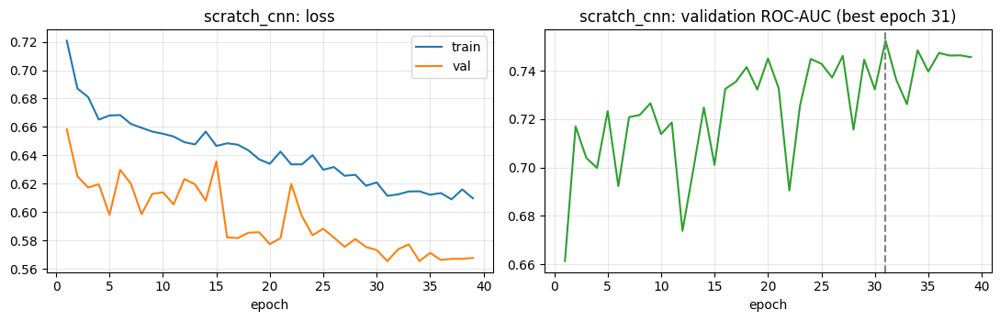


===== resnet18_frozen  (epochs=20, lr=0.001) =====
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 184MB/s]


resnet18_frozen | Epoch 1/20 | Train Loss: 0.7686 | Val Loss: 0.6595 | Val AUC: 0.6954 | Time: 2.3s
resnet18_frozen | Epoch 2/20 | Train Loss: 0.7175 | Val Loss: 0.6000 | Val AUC: 0.7255 | Time: 2.3s
resnet18_frozen | Epoch 3/20 | Train Loss: 0.6743 | Val Loss: 0.5752 | Val AUC: 0.7650 | Time: 2.3s
resnet18_frozen | Epoch 4/20 | Train Loss: 0.6701 | Val Loss: 0.6151 | Val AUC: 0.7424 | Time: 2.3s
resnet18_frozen | Epoch 5/20 | Train Loss: 0.6497 | Val Loss: 0.5795 | Val AUC: 0.7578 | Time: 2.3s
resnet18_frozen | Epoch 6/20 | Train Loss: 0.6472 | Val Loss: 0.5929 | Val AUC: 0.7372 | Time: 2.3s
resnet18_frozen | Epoch 7/20 | Train Loss: 0.6502 | Val Loss: 0.6201 | Val AUC: 0.7403 | Time: 2.3s
resnet18_frozen | Epoch 8/20 | Train Loss: 0.6598 | Val Loss: 0.5772 | Val AUC: 0.7597 | Time: 2.3s
resnet18_frozen | Epoch 9/20 | Train Loss: 0.6384 | Val Loss: 0.5827 | Val AUC: 0.7643 | Time: 2.3s
resnet18_frozen | Epoch 10/20 | Train Loss: 0.6434 | Val Loss: 0.5688 | Val AUC: 0.7733 | Time: 2.4s

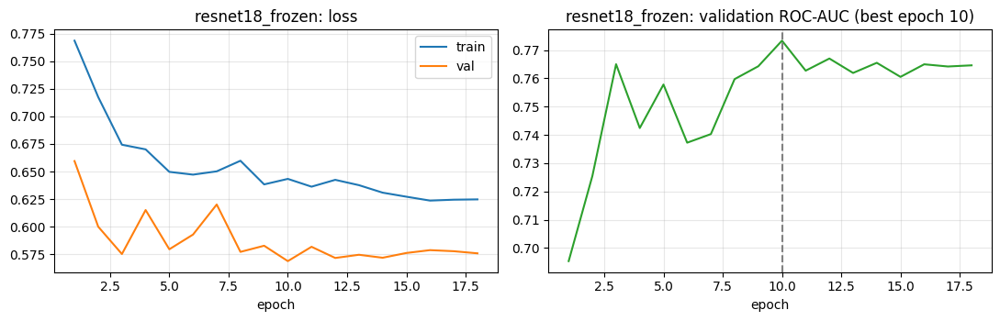


===== resnet18_partial  (epochs=25, lr=0.0003) =====
resnet18_partial | Epoch 1/25 | Train Loss: 0.8441 | Val Loss: 0.6282 | Val AUC: 0.7112 | Time: 2.4s
resnet18_partial | Epoch 2/25 | Train Loss: 0.7439 | Val Loss: 0.5958 | Val AUC: 0.7318 | Time: 2.4s
resnet18_partial | Epoch 3/25 | Train Loss: 0.6613 | Val Loss: 0.5396 | Val AUC: 0.8022 | Time: 2.3s
resnet18_partial | Epoch 4/25 | Train Loss: 0.6220 | Val Loss: 0.5448 | Val AUC: 0.7888 | Time: 2.3s
resnet18_partial | Epoch 5/25 | Train Loss: 0.5917 | Val Loss: 0.6383 | Val AUC: 0.7246 | Time: 2.4s
resnet18_partial | Epoch 6/25 | Train Loss: 0.6033 | Val Loss: 0.5422 | Val AUC: 0.7841 | Time: 2.3s
resnet18_partial | Epoch 7/25 | Train Loss: 0.5767 | Val Loss: 0.5222 | Val AUC: 0.8086 | Time: 2.4s
resnet18_partial | Epoch 8/25 | Train Loss: 0.5677 | Val Loss: 0.5285 | Val AUC: 0.8158 | Time: 2.4s
resnet18_partial | Epoch 9/25 | Train Loss: 0.5517 | Val Loss: 0.5175 | Val AUC: 0.8155 | Time: 2.4s
resnet18_partial | Epoch 10/25 | Trai

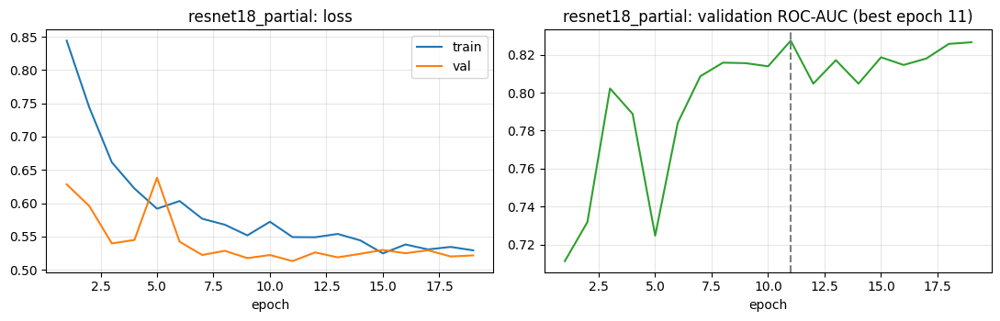


===== resnet18_full  (epochs=25, lr=0.0001) =====
resnet18_full | Epoch 1/25 | Train Loss: 0.8293 | Val Loss: 0.7390 | Val AUC: 0.6998 | Time: 2.6s
resnet18_full | Epoch 2/25 | Train Loss: 0.7326 | Val Loss: 0.6622 | Val AUC: 0.7308 | Time: 2.6s
resnet18_full | Epoch 3/25 | Train Loss: 0.6753 | Val Loss: 0.6193 | Val AUC: 0.7603 | Time: 2.6s
resnet18_full | Epoch 4/25 | Train Loss: 0.6549 | Val Loss: 0.6093 | Val AUC: 0.7554 | Time: 2.6s
resnet18_full | Epoch 5/25 | Train Loss: 0.6226 | Val Loss: 0.6101 | Val AUC: 0.7521 | Time: 2.6s
resnet18_full | Epoch 6/25 | Train Loss: 0.6168 | Val Loss: 0.5774 | Val AUC: 0.7550 | Time: 2.6s
resnet18_full | Epoch 7/25 | Train Loss: 0.5880 | Val Loss: 0.5887 | Val AUC: 0.7833 | Time: 2.6s
resnet18_full | Epoch 8/25 | Train Loss: 0.5713 | Val Loss: 0.5632 | Val AUC: 0.7893 | Time: 2.6s
resnet18_full | Epoch 9/25 | Train Loss: 0.5667 | Val Loss: 0.5571 | Val AUC: 0.7875 | Time: 2.6s
resnet18_full | Epoch 10/25 | Train Loss: 0.5604 | Val Loss: 0.5563

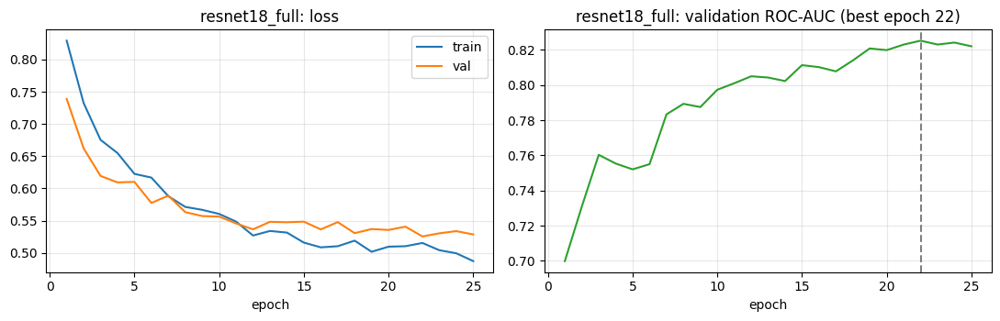

,best epoch,val ROC-AUC,val balanced acc,val loss
scratch_cnn,31.0,0.752,0.682,0.566
resnet18_frozen,10.0,0.773,0.689,0.569
resnet18_partial,11.0,0.827,0.747,0.513
resnet18_full,22.0,0.825,0.752,0.525


Best run by validation ROC-AUC: resnet18_partial


In [45]:
trained, histories, bests = {}, {}, {}
for name, (epochs, lr) in RUNS.items():
    print(f"\n===== {name}  (epochs={epochs}, lr={lr}) =====")
    trained[name], histories[name], bests[name] = train_model(name, epochs, lr)

val_table = pd.DataFrame({k: {"best epoch": v["epoch"], "val ROC-AUC": v["auc"], "val balanced acc": v.get("bacc", np.nan),
                              "val loss": v["loss"]} for k, v in bests.items()}).T.round(3)
val_table.to_csv(f"{OUT_DIR}/validation_comparison.csv")
display(val_table)
best_name = val_table["val ROC-AUC"].idxmax()
print("Best run by validation ROC-AUC:", best_name)

### Independent Reproduction Check

Ziyad independently reran the Phase 1 training notebook and compared the validation results with the original team run.

| Model | Original ROC-AUC | Independent ROC-AUC |
|---|---:|---:|
| Scratch CNN | 0.764 | 0.752 |
| ResNet18 Frozen | 0.778 | 0.773 |
| ResNet18 Partial | 0.835 | 0.827 |
| ResNet18 Full | 0.825 | 0.825 |

The independent run produced comparable validation ROC-AUC results across all four models. ResNet18 Partial achieved the highest validation ROC-AUC in both runs. The small differences indicate that the main experimental findings were reproducible, although the numerical results were not identical.

In [ ]:
!nvidia-smi

## 10. Final Evaluation on the Test Set

After selecting the best model using the validation results, we evaluated all four models on the official test set.

We used the test set only for the final evaluation.

The following metrics were calculated for each model:

- **Accuracy:** The percentage of correctly classified images, with a 95% confidence interval.
- **Balanced Accuracy:** The average recall across both classes.
- **Precision, Recall, and F1-score:** To measure performance for benign and malignant cases.
- **ROC-AUC:** To measure how well the model separates the two classes, with a 95% confidence interval.
- **PR-AUC:** To evaluate precision and recall performance.
- **ECE:** To measure how well the predicted probabilities match the actual results.
- **Confusion Matrix:** To show correct and incorrect predictions.

Confidence intervals were calculated using patient-level bootstrap sampling because multiple images may belong to the same

Test set, IMG_SIZE=64, threshold=0.5, n=704 images, 349 patients


model,scratch_cnn,resnet18_frozen,resnet18_partial,resnet18_full
accuracy,"0.517 [0.467, 0.568]","0.575 [0.530, 0.617]","0.679 [0.641, 0.720]","0.638 [0.599, 0.679]"
balanced acc,0.576,0.608,0.686,0.654
P benign,0.756,0.745,0.784,0.768
R benign,0.304,0.458,0.652,0.579
F1 benign,0.433,0.567,0.712,0.66
P malignant,0.44,0.474,0.572,0.528
R malignant,0.848,0.757,0.721,0.728
F1 malignant,0.579,0.583,0.638,0.612
ROC-AUC,"0.644 [0.588, 0.699]","0.658 [0.605, 0.707]","0.751 [0.709, 0.792]","0.741 [0.698, 0.782]"
PR-AUC,0.548,0.569,0.675,0.67


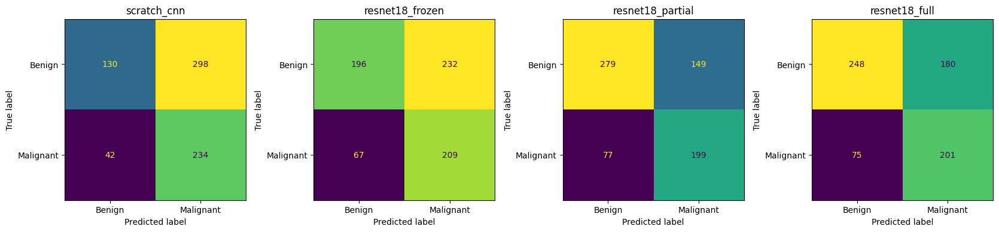

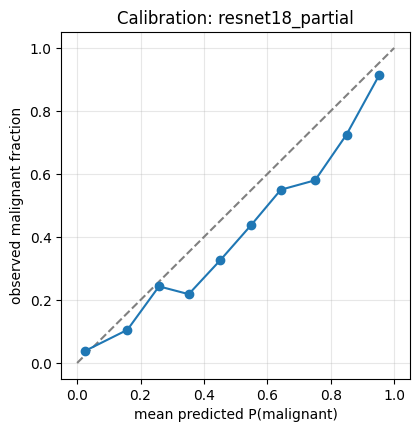

In [46]:
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_fscore_support, accuracy_score)


@torch.no_grad()
def predict(model, loader):
    model.eval(); P, Y = [], []
    for xb, yb in loader:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            lo = model(xb.to(device))
        P.append(torch.softmax(lo.float(), 1)[:, 1].cpu()); Y.append(yb)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()


def expected_calibration_error(y, p, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1); ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p <= hi) if lo == 0 else (p > lo) & (p <= hi)
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(ece)


def cluster_bootstrap(y, p, groups, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    pats = np.unique(groups)
    idx_by = {g: np.where(groups == g)[0] for g in pats}
    accs, aucs = [], []
    for _ in range(n_boot):
        idx = np.concatenate([idx_by[g] for g in rng.choice(pats, len(pats), replace=True)])
        yy, pp = y[idx], p[idx]
        accs.append(((pp >= 0.5) == yy).mean())
        if len(np.unique(yy)) == 2:
            aucs.append(roc_auc_score(yy, pp))
    return np.percentile(accs, [2.5, 97.5]), np.percentile(aucs, [2.5, 97.5])


_, _, test_loader = make_loaders()
test_groups = test_meta["patient_id"].to_numpy()
test_p, test_y = {}, None
rows = []
for name, model in trained.items():
    p, y = predict(model.to(device), test_loader)
    test_p[name], test_y = p, y
    yhat = (p >= 0.5).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y, yhat, labels=[0, 1], zero_division=0)
    (a_lo, a_hi), (u_lo, u_hi) = cluster_bootstrap(y, p, test_groups)
    rows.append({"model": name,
                 "accuracy": f"{accuracy_score(y, yhat):.3f} [{a_lo:.3f}, {a_hi:.3f}]",
                 "balanced acc": round(balanced_accuracy_score(y, yhat), 3),
                 "P benign": round(pr[0], 3), "R benign": round(rc[0], 3), "F1 benign": round(f1[0], 3),
                 "P malignant": round(pr[1], 3), "R malignant": round(rc[1], 3), "F1 malignant": round(f1[1], 3),
                 "ROC-AUC": f"{roc_auc_score(y, p):.3f} [{u_lo:.3f}, {u_hi:.3f}]",
                 "PR-AUC": round(average_precision_score(y, p), 3),
                 "ECE": round(expected_calibration_error(y, p), 3)})
test_table = pd.DataFrame(rows).set_index("model")
test_table.to_csv(f"{OUT_DIR}/test_results.csv")
print(f"Test set, IMG_SIZE={IMG_SIZE}, threshold=0.5, n={len(test_y)} images, {len(np.unique(test_groups))} patients")
display(test_table.T)

fig, axes = plt.subplots(1, len(trained), figsize=(4.2 * len(trained), 4))
for ax, name in zip(np.atleast_1d(axes), trained):
    ConfusionMatrixDisplay(confusion_matrix(test_y, (test_p[name] >= 0.5).astype(int)),
                           display_labels=["Benign", "Malignant"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); fig.savefig(f"{OUT_DIR}/test_confusion_matrices.png", dpi=120); plt.show()

# reliability diagram of the best-by-validation model
p = test_p[best_name]
edges = np.linspace(0, 1, 11); mids, accs = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (p >= lo) & (p <= hi) if lo == 0 else (p > lo) & (p <= hi)
    if m.sum() >= 3:
        mids.append(p[m].mean()); accs.append(test_y[m].mean())
plt.figure(figsize=(4.5, 4.5)); plt.plot([0, 1], [0, 1], "--", color="gray"); plt.plot(mids, accs, "o-")
plt.xlabel("mean predicted P(malignant)"); plt.ylabel("observed malignant fraction")
plt.title(f"Calibration: {best_name}"); plt.grid(alpha=.3); plt.show()

# final report run in W&B
tracker.start("final-test-report", {"img_size": IMG_SIZE, "seed": SEED, "split": "official test", "threshold": 0.5},
              job_type="report")
if tracker.run is not None:
    tracker.run.log({"test_results": wandb.Table(dataframe=test_table.reset_index())})
tracker.log_fig("confusion_matrices", fig)
tracker.finish()

## 11. Error Analysis and Data Improvement

We selected the best model based on validation ROC-AUC (`resnet18_partial`) and examined its predictions on the test set.

We reviewed the incorrect predictions using the error gallery and compared the model performance across different groups:

- Mass and calcification cases.
- CC and MLO image views.
- Small, medium, and large ROI images.

The purpose of this analysis is to understand where the model makes more mistakes and identify possible improvements to the dataset.

The final data improvement plan is provided at the end of this section.

resnet18_partial: 226 errors / 704 | false negatives: 77 | false positives: 149


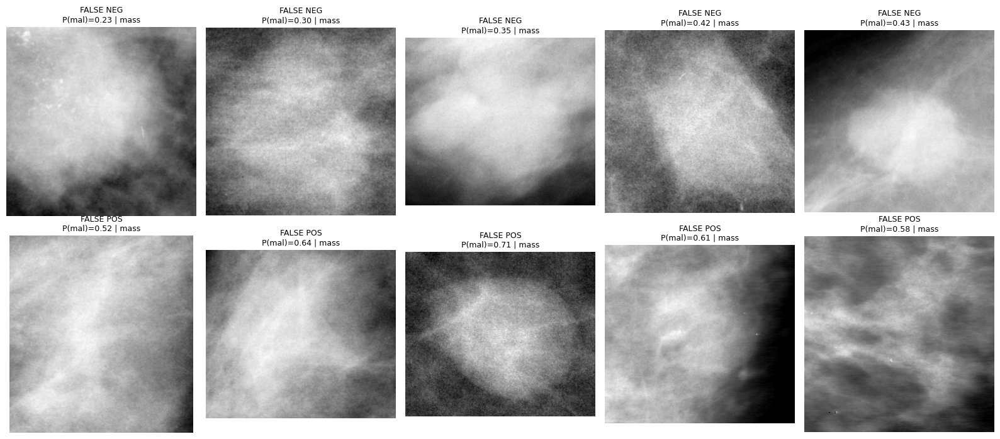

In [47]:
p = test_p[best_name]; y = test_y; yhat = (p >= 0.5).astype(int)
wrong = np.where(yhat != y)[0]
fn = [i for i in wrong if y[i] == 1][:5]      # missed malignant
fp = [i for i in wrong if y[i] == 0][:5]      # false alarms
print(f"{best_name}: {len(wrong)} errors / {len(y)} | false negatives: {int((y[wrong] == 1).sum())} | "
      f"false positives: {int((y[wrong] == 0).sum())}")

idxs = fn + fp
if idxs:
    fig, axes = plt.subplots(2, 5, figsize=(16, 7))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), idxs):
        ax.imshow(read_gray(test_meta.loc[i, "matched_image_path"]), cmap="gray")
        ax.set_title(("FALSE NEG" if y[i] == 1 else "FALSE POS") + f"\nP(mal)={p[i]:.2f} | {test_meta.loc[i, 'case_type']}", fontsize=9)
    plt.tight_layout(); fig.savefig(f"{OUT_DIR}/error_gallery.png", dpi=120); plt.show()

In [48]:
# sub-group analysis: where does the model fail?
def roi_hw(path):
    h, w = inspect_file(path)["shape"]; return h * w

ea = test_meta.copy()
ea["p"], ea["pred"], ea["error"] = p, yhat, (yhat != y).astype(int)
ea["roi_pixels"] = ea["matched_image_path"].map(roi_hw)
ea["roi_size"] = pd.qcut(ea["roi_pixels"], 3, labels=["small", "medium", "large"], duplicates="drop")


def group_stats(df, col):
    out = []
    for k, g in df.groupby(col, observed=True):
        out.append({col: k, "n": len(g), "malignant %": round(100 * g["label"].mean(), 1),
                    "error rate": round(g["error"].mean(), 3),
                    "ROC-AUC": round(roc_auc_score(g["label"], g["p"]), 3) if g["label"].nunique() == 2 else np.nan})
    return pd.DataFrame(out)

for col in ["case_type", "image view", "roi_size"]:
    display(group_stats(ea, col))

,case_type,n,malignant %,error rate,ROC-AUC
0,calcification,326,39.6,0.340,0.729
1,mass,378,38.9,0.304,0.778


,image view,n,malignant %,error rate,ROC-AUC
0,CC,326,39.0,0.316,0.765
1,MLO,378,39.4,0.325,0.738


,roi_size,n,malignant %,error rate,ROC-AUC
0,small,235,28.1,0.272,0.735
1,medium,234,38.9,0.333,0.744
2,large,235,50.6,0.357,0.729


### Data-improvement plan

*Draft based on the outputs of this run (model selected on validation: `resnet18_partial`; test set, `IMG_SIZE=64`, threshold 0.5). Check each row against the gallery and tables before submitting.*

**Error profile:** 258 errors in 704 test images: 201 false positives and 57 false negatives. In the 10 errors shown in the gallery (the first 5 of each kind, not a random sample) all are masses and P(malignant) lies between 0.40 and 0.67, i.e. borderline predictions.

| # | Observed failure | Evidence | Planned data fix |
|---|---|---|---|
| 1 | Lesions are hard to distinguish at the current resolution; predictions are borderline | Gallery (probabilities 0.40-0.67); test ROC-AUC only 0.65-0.76 | Re-run the identical split at higher resolution (`IMG_SIZE=128`, then 224) on a GPU and compare in W&B |
| 2 | Some crops are mostly background or breast edge, so the lesion is barely visible | Second false negative in the gallery | Use the ROI mask to tighten crops or flag crops with large black background; re-run the mask-like / quality check and re-audit |
| 3 | ROI size correlates with the label and accuracy varies with size | Malignant share 28.1 % (small), 38.9 % (medium), 50.6 % (large); ROC-AUC lowest for small ROIs (0.699) | Report metrics per size group; test on size-matched subsets to check the model does not rely on size; rebalance sampling by size if it does |
| 4 | Lesion-to-label linking across views is unreliable | 3 of 1486 multi-view groups have conflicting labels, but patient P_00419 shows the same abnormality id can be two different lesions | Link views with file/UID information instead of the abnormality id; finish the manual audit (upper bound) |
| 5 | Validation looks better than test | Validation ROC-AUC 0.815-0.828 vs. test 0.73-0.76 for the fine-tuned models | Use patient-grouped cross-validation on the training set to get a more stable estimate; report the gap in the dataset card |

Then re-train the affected runs and compare them against this run in W&B.

## 12. Dataset Card and Reproducibility Files

In this section, we create three files to document the project and make it easier to reproduce:

- **`DATASET_CARD.md`:** Describes the dataset, cleaning steps, data splits, and known limitations.
- **`requirements.txt`:** Lists the Python libraries and their installed versions.
- **`config.json`:** Saves the main experiment settings, including the random seed, image size, batch size, training settings, and selected model.

These files help document how the project was prepared and run.

In [49]:
def md_table(df):
    try:
        return df.to_markdown()
    except ImportError:                      # 'tabulate' not installed
        return "```\n" + df.to_string() + "\n```"


excl_df = pd.DataFrame(excluded) if excluded else pd.DataFrame(columns=["reason"])
excl_counts = excl_df["reason"].value_counts().to_dict()
comp = pd.crosstab([clean["split"], clean["case_type"]], clean["pathology"])

card = f"""# Dataset Card: CBIS-DDSM cropped ROI images (benign vs. malignant)

## Overview
- **Task:** binary classification (0 = benign incl. benign-without-callback, 1 = malignant) of cropped mammography ROI images.
- **Source:** CBIS-DDSM (Curated Breast Imaging Subset of DDSM), JPEG version from the Kaggle mirror `awsaf49/cbis-ddsm-breast-cancer-image-dataset`.
- **Licence:** listed as CC-BY-SA-3.0 by the Kaggle CLI for this mirror. Verify the terms of the original TCIA collection before any redistribution. Images are **not** redistributed or committed to the repository.
- **Content:** mass and calcification cases; official train / test CSVs; pathology label from biopsy.

## Composition after cleaning
{md_table(comp)}

## Splits (patient-level, leakage-safe)
- Test = official CBIS-DDSM test set. Validation = one patient-grouped, label-stratified fold of the official train set (seed {SEED}).
- Verified in code: no patient appears in more than one of train / val / test (mass and calcification combined).

{md_table(balance_df)}

## Cleaning
- Rows in the original CSVs: {len(raw)}. Excluded rows: {len(excluded)}. Reasons: {excl_counts if excl_counts else 'none'}.
- Excluded: unmatched, ambiguous, unreadable and mask-like files; duplicate images (same file bytes; train copies removed when also in test; conflicting-label duplicates removed); train rows of patients that also appear in test.
- Full log: `outputs/excluded_files.csv` and `outputs/match_log.csv`.

## Preprocessing and augmentation
- ROI crop padded to a square (black) and resized to {IMG_SIZE}x{IMG_SIZE}, grayscale, normalised with train mean/std ({MEAN:.4f} / {STD:.4f}).
- Training augmentation only: horizontal/vertical flip, rotation up to 15 degrees, translation 5 %, scale 0.9-1.1, brightness/contrast jitter 0.2.

## Label audit
- Automatic lesion-view consistency check: {n_bad} of {n_multi} multi-view lesion groups have conflicting labels (`outputs/label_consistency_flags.csv`).
- Manual review of a random sample: {audit_summary}.
- The audit checks image/label correspondence, not the biopsy result itself.

## Known limitations and biases
- Digitised film mammograms from a historical US collection; scanner, patient population and imaging protocol may not match modern digital mammography.
- ROI crops vary in size and context; some lesions are very small after resizing.
- Mass and calcification cases differ visually and are pooled in one classifier.
- One patient can contribute several images (views, lesions): metrics are correlated, so confidence intervals are computed over patients.
- Pathology labels are taken from the dataset and were not independently re-verified.

## Intended and out-of-scope use
- Intended: coursework on dataset preparation and image classification.
- **Out of scope:** any clinical, diagnostic or screening use.
"""
open("DATASET_CARD.md", "w").write(card)
print(card[:1500], "...")

# Dataset Card: CBIS-DDSM cropped ROI images (benign vs. malignant)

## Overview
- **Task:** binary classification (0 = benign incl. benign-without-callback, 1 = malignant) of cropped mammography ROI images.
- **Source:** CBIS-DDSM (Curated Breast Imaging Subset of DDSM), JPEG version from the Kaggle mirror `awsaf49/cbis-ddsm-breast-cancer-image-dataset`.
- **Licence:** listed as CC-BY-SA-3.0 by the Kaggle CLI for this mirror. Verify the terms of the original TCIA collection before any redistribution. Images are **not** redistributed or committed to the repository.
- **Content:** mass and calcification cases; official train / test CSVs; pathology label from biopsy.

## Composition after cleaning
|                            |   BENIGN |   BENIGN_WITHOUT_CALLBACK |   MALIGNANT |
|:---------------------------|---------:|--------------------------:|------------:|
| ('test', 'calcification')  |      130 |                        67 |         129 |
| ('test', 'mass')           |      194 |  

In [50]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [51]:
from importlib.metadata import version, PackageNotFoundError

lines = []
for pkg in ["torch", "torchvision", "numpy", "pandas", "scikit-learn", "scipy", "opencv-python", "opencv-python-headless",
            "matplotlib", "tqdm", "wandb", "tabulate"]:
    try:
        lines.append(f"{pkg}=={version(pkg)}")
    except PackageNotFoundError:
        pass
open("requirements.txt", "w").write("\n".join(lines) + "\n")

config = dict(SEED=SEED, IMG_SIZE=IMG_SIZE, BATCH_SIZE=BATCH_SIZE, PRETRAINED=PRETRAINED, RUNS=RUNS, PATIENCE=PATIENCE,
              OVERLAP_POLICY=OVERLAP_POLICY, VAL_FRACTION_FOLDS=VAL_FRACTION_FOLDS, WANDB_PROJECT=WANDB_PROJECT,
              best_run_by_validation=best_name)
json.dump(config, open("config.json", "w"), indent=2)
print(open("requirements.txt").read()); print(json.dumps(config, indent=2))

torch==2.14.1+cu130
torchvision==0.29.1+cu130
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
scipy==1.16.3
opencv-python==5.0.0.93
opencv-python-headless==5.0.0.93
matplotlib==3.10.0
tqdm==4.67.3
wandb==0.28.1
tabulate==0.9.0

{
  "SEED": 42,
  "IMG_SIZE": 64,
  "BATCH_SIZE": 64,
  "PRETRAINED": true,
  "RUNS": {
    "scratch_cnn": [
      40,
      0.001
    ],
    "resnet18_frozen": [
      20,
      0.001
    ],
    "resnet18_partial": [
      25,
      0.0003
    ],
    "resnet18_full": [
      25,
      0.0001
    ]
  },
  "PATIENCE": 8,
  "OVERLAP_POLICY": "drop_from_train",
  "VAL_FRACTION_FOLDS": 5,
  "WANDB_PROJECT": "ai251p-cbis-ddsm",
  "best_run_by_validation": "resnet18_partial"
}


In [52]:
import os
import shutil

backup_dir = "/content/drive/MyDrive/CBIS_DDSM_Project"
os.makedirs(backup_dir, exist_ok=True)

for folder in ["checkpoints", "outputs"]:
    if os.path.isdir(folder):
        shutil.copytree(folder, os.path.join(backup_dir, folder), dirs_exist_ok=True)
        print(f"Saved: {folder}")
    else:
        print(f"Missing: {folder}")

for filename in ["DATASET_CARD.md", "requirements.txt", "config.json"]:
    if os.path.isfile(filename):
        shutil.copy2(filename, backup_dir)
        print(f"Saved: {filename}")
    else:
        print(f"Missing: {filename}")

print("Backup completed:", backup_dir)

Saved: checkpoints
Saved: outputs
Saved: DATASET_CARD.md
Saved: requirements.txt
Saved: config.json
Backup completed: /content/drive/MyDrive/CBIS_DDSM_Project


## 13. Limitations and Known Risks

There are some limitations in this project that should be considered:

- **Data Leakage:** We used patient-level splitting and checked that no patient appeared in more than one set. Duplicate images were also removed, and excluded rows were recorded.
- **Label Quality:** The labels are based on biopsy results from the dataset. Our checks focused on image matching and label consistency, not on verifying the medical diagnosis.
- **Dataset Type:** The dataset contains digitised film mammograms, so the results may not apply directly to modern digital mammography systems.
- **Statistical Limitations:** The test set contains images from 349 patients. Since some patients have multiple images, we used patient-level bootstrap to calculate confidence intervals.
- **Image Resolution:** Resizing ROI images to 64 × 64 may remove important details, especially in calcification cases.
- **Project Scope:** This phase focuses on binary image classification only. Detection, segmentation, ONNX export, HTTP service, and benchmarking are planned for Phase 2.
- **Clinical Use:** This project is for academic purposes only and is not intended for medical diagnosis.